# Aggregate Loss & Capital Modelling

## 1. Objective

This notebook combines the fitted claim-frequency and claim-severity models to simulate the portfolio's annual aggregate insurance losses.

The objective is to construct the annual loss distribution required for capital and risk analysis, including:

- Expected annual loss
- Annual loss volatility
- Value at Risk (VaR)
- Tail Value at Risk / Expected Shortfall (TVaR)
- Unexpected loss
- Tail-risk sensitivity
- Stress and scenario analysis

The analysis represents a simplified insurance-risk capital model and should not be interpreted as a regulatory Solvency Capital Requirement (SCR).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Base model inputs established in previous notebooks
EXPECTED_ANNUAL_CLAIMS = 26578.40
NB_ALPHA = 1.074198

OBSERVED_MEAN_SEVERITY = 2265.51
MODELLED_MEAN_SEVERITY = 2595.62
MAXIMUM_MODELLED_LOSS = 4075400.56

print("BASE CAPITAL MODEL INPUTS")
print(f"Expected annual claims:       {EXPECTED_ANNUAL_CLAIMS:,.2f}")
print(f"Negative Binomial alpha:      {NB_ALPHA:.6f}")
print(f"Observed mean severity:       £{OBSERVED_MEAN_SEVERITY:,.2f}")
print(f"Modelled mean severity:       £{MODELLED_MEAN_SEVERITY:,.2f}")
print(f"Maximum modelled loss:        £{MAXIMUM_MODELLED_LOSS:,.2f}")

# Aggregate Loss & Capital Modelling

## 1. Objective

This notebook combines the fitted claim-frequency and claim-severity models to simulate the portfolio's annual aggregate insurance losses.

The objective is to construct the annual loss distribution required for capital and risk analysis, including:

- Expected annual loss
- Annual loss volatility
- Value at Risk (VaR)
- Tail Value at Risk / Expected Shortfall (TVaR)
- Unexpected loss
- Tail-risk sensitivity
- Stress and scenario analysis

The analysis represents a simplified insurance-risk capital model and should not be interpreted as a regulatory Solvency Capital Requirement (SCR).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Base model inputs established in previous notebooks
EXPECTED_ANNUAL_CLAIMS = 26578.40
NB_ALPHA = 1.074198

OBSERVED_MEAN_SEVERITY = 2265.51
MODELLED_MEAN_SEVERITY = 2595.62
MAXIMUM_MODELLED_LOSS = 4075400.56

print("BASE CAPITAL MODEL INPUTS")
print(f"Expected annual claims:       {EXPECTED_ANNUAL_CLAIMS:,.2f}")
print(f"Negative Binomial alpha:      {NB_ALPHA:.6f}")
print(f"Observed mean severity:       £{OBSERVED_MEAN_SEVERITY:,.2f}")
print(f"Modelled mean severity:       £{MODELLED_MEAN_SEVERITY:,.2f}")
print(f"Maximum modelled loss:        £{MAXIMUM_MODELLED_LOSS:,.2f}")

BASE CAPITAL MODEL INPUTS
Expected annual claims:       26,578.40
Negative Binomial alpha:      1.074198
Observed mean severity:       £2,265.51
Modelled mean severity:       £2,595.62
Maximum modelled loss:        £4,075,400.56


## 2. Annual Claim Frequency Simulation

Annual claim counts are simulated using a Negative Binomial distribution, consistent with the overdispersion identified during frequency modelling.

The simulation represents variation in the number of claims arising over a one-year risk horizon.

In [3]:
# Simulate annual claim counts using the Negative Binomial model

N_SIMULATIONS = 100_000

# Convert NB2 mean/dispersion parameterisation to NumPy parameters
nb_n = 1 / NB_ALPHA
nb_p = nb_n / (nb_n + EXPECTED_ANNUAL_CLAIMS)

annual_claim_counts = rng.negative_binomial(
    n=nb_n,
    p=nb_p,
    size=N_SIMULATIONS
)

print("ANNUAL CLAIM FREQUENCY SIMULATION")
print(f"Simulations:                 {N_SIMULATIONS:,}")
print(f"Target expected claims:      {EXPECTED_ANNUAL_CLAIMS:,.2f}")
print(f"Simulated mean claims:       {annual_claim_counts.mean():,.2f}")
print(f"Simulated median claims:     {np.median(annual_claim_counts):,.0f}")
print(f"Simulated standard deviation:{annual_claim_counts.std():,.2f}")
print(f"Minimum simulated claims:    {annual_claim_counts.min():,}")
print(f"Maximum simulated claims:    {annual_claim_counts.max():,}")

ANNUAL CLAIM FREQUENCY SIMULATION
Simulations:                 100,000
Target expected claims:      26,578.40
Simulated mean claims:       26,497.28
Simulated median claims:     17,829
Simulated standard deviation:27,371.34
Minimum simulated claims:    0
Maximum simulated claims:    381,818


In [4]:
# Base annual portfolio claim-count simulation
# Poisson is used at aggregate portfolio level.
# Policy-level Negative Binomial overdispersion was assessed separately
# in the frequency modelling notebook.

N_SIMULATIONS = 100_000

annual_claim_counts = rng.poisson(
    lam=EXPECTED_ANNUAL_CLAIMS,
    size=N_SIMULATIONS
)

print("BASE PORTFOLIO FREQUENCY SIMULATION")
print(f"Simulations:                  {N_SIMULATIONS:,}")
print(f"Target expected claims:       {EXPECTED_ANNUAL_CLAIMS:,.2f}")
print(f"Simulated mean claims:        {annual_claim_counts.mean():,.2f}")
print(f"Simulated median claims:      {np.median(annual_claim_counts):,.0f}")
print(f"Simulated standard deviation: {annual_claim_counts.std():,.2f}")
print(f"Minimum simulated claims:     {annual_claim_counts.min():,}")
print(f"Maximum simulated claims:     {annual_claim_counts.max():,}")

BASE PORTFOLIO FREQUENCY SIMULATION
Simulations:                  100,000
Target expected claims:       26,578.40
Simulated mean claims:        26,578.41
Simulated median claims:      26,578
Simulated standard deviation: 162.88
Minimum simulated claims:     25,828
Maximum simulated claims:     27,362


## 3. Aggregate Annual Loss Simulation

The annual aggregate loss model combines the simulated portfolio claim frequency with the fitted heavy-tailed severity model.

To keep the Monte Carlo simulation computationally efficient, aggregate losses are simulated using a frequency–severity approximation rather than explicitly generating every individual claim for every simulated year.

The objective is to estimate the distribution of annual insurance losses required for subsequent VaR, TVaR and unexpected-loss analysis.

In [5]:
# Aggregate-loss moment parameters

MEAN_SEVERITY = MODELLED_MEAN_SEVERITY

# Use the empirical severity variance from the observed claims data
# established during severity modelling.
SEVERITY_SD = 29371.03
SEVERITY_VARIANCE = SEVERITY_SD ** 2

# Compound Poisson moments
expected_aggregate_loss = (
    EXPECTED_ANNUAL_CLAIMS * MEAN_SEVERITY
)

aggregate_variance = (
    EXPECTED_ANNUAL_CLAIMS
    * (SEVERITY_VARIANCE + MEAN_SEVERITY ** 2)
)

aggregate_sd = np.sqrt(aggregate_variance)

print("AGGREGATE LOSS MOMENT ESTIMATES")
print(f"Expected annual loss: £{expected_aggregate_loss:,.2f}")
print(f"Aggregate loss SD:    £{aggregate_sd:,.2f}")

AGGREGATE LOSS MOMENT ESTIMATES
Expected annual loss: £68,987,426.61
Aggregate loss SD:    £4,806,986.44


In [6]:
# Hybrid aggregate-loss simulation parameters

TAIL_PROBABILITY = 0.025
TAIL_THRESHOLD = 8156.01

# GPD parameters fitted at the 97.5% threshold
GPD_XI = 1.0327
GPD_BETA = 5551.67

expected_tail_claims = (
    EXPECTED_ANNUAL_CLAIMS * TAIL_PROBABILITY
)

expected_body_claims = (
    EXPECTED_ANNUAL_CLAIMS * (1 - TAIL_PROBABILITY)
)

print("HYBRID AGGREGATE MODEL SETUP")
print(f"Expected annual claims:      {EXPECTED_ANNUAL_CLAIMS:,.2f}")
print(f"Expected body claims:        {expected_body_claims:,.2f}")
print(f"Expected tail claims:        {expected_tail_claims:,.2f}")
print(f"Tail threshold:              £{TAIL_THRESHOLD:,.2f}")
print(f"GPD shape xi:                {GPD_XI:.4f}")
print(f"GPD scale beta:              £{GPD_BETA:,.2f}")

HYBRID AGGREGATE MODEL SETUP
Expected annual claims:      26,578.40
Expected body claims:        25,913.94
Expected tail claims:        664.46
Tail threshold:              £8,156.01
GPD shape xi:                1.0327
GPD scale beta:              £5,551.67


In [7]:
# Load observed severity data and calculate body moments

severity_data = pd.read_csv(
    "../data/processed/freMTPL2sev.csv"
)

body_claims = severity_data.loc[
    severity_data["ClaimAmount"] <= TAIL_THRESHOLD,
    "ClaimAmount"
]

BODY_MEAN = body_claims.mean()
BODY_SD = body_claims.std()

print("BODY SEVERITY PARAMETERS")
print(f"Body observations:     {len(body_claims):,}")
print(f"Body mean severity:    £{BODY_MEAN:,.2f}")
print(f"Body severity SD:      £{BODY_SD:,.2f}")
print(f"Maximum body severity: £{body_claims.max():,.2f}")

BODY SEVERITY PARAMETERS
Body observations:     25,782
Body mean severity:    £1,270.34
Body severity SD:      £1,116.46
Maximum body severity: £8,138.07


In [8]:
# Hybrid Monte Carlo aggregate-loss simulation

from scipy import stats

N_SIMULATIONS = 100_000

# -----------------------------
# BODY COMPONENT
# -----------------------------

body_counts = rng.poisson(
    lam=expected_body_claims,
    size=N_SIMULATIONS
)

# Conditional compound-sum moments
body_loss_mean = body_counts * BODY_MEAN

body_loss_sd = np.sqrt(body_counts) * BODY_SD

body_aggregate_losses = rng.normal(
    loc=body_loss_mean,
    scale=body_loss_sd
)

# Prevent numerical negative aggregate losses
body_aggregate_losses = np.maximum(body_aggregate_losses, 0)


# -----------------------------
# TAIL COMPONENT
# -----------------------------

tail_counts = rng.poisson(
    lam=expected_tail_claims,
    size=N_SIMULATIONS
)

tail_aggregate_losses = np.zeros(N_SIMULATIONS)

MAXIMUM_MODELLED_LOSS = 4_075_400.56

for i, n_tail in enumerate(tail_counts):

    if n_tail > 0:

        excess_losses = stats.genpareto.rvs(
            c=GPD_XI,
            loc=0,
            scale=GPD_BETA,
            size=n_tail,
            random_state=rng
        )

        tail_losses = TAIL_THRESHOLD + excess_losses

        # Apply modelling limit established in severity analysis
        tail_losses = np.minimum(
            tail_losses,
            MAXIMUM_MODELLED_LOSS
        )

        tail_aggregate_losses[i] = tail_losses.sum()


# -----------------------------
# TOTAL ANNUAL LOSS
# -----------------------------

annual_aggregate_losses = (
    body_aggregate_losses
    + tail_aggregate_losses
)

print("AGGREGATE LOSS SIMULATION COMPLETE")
print(f"Simulated years:       {N_SIMULATIONS:,}")
print(f"Mean annual loss:      £{annual_aggregate_losses.mean():,.2f}")
print(f"Median annual loss:    £{np.median(annual_aggregate_losses):,.2f}")
print(f"Annual loss SD:        £{annual_aggregate_losses.std():,.2f}")
print(f"Minimum annual loss:   £{annual_aggregate_losses.min():,.2f}")
print(f"Maximum annual loss:   £{annual_aggregate_losses.max():,.2f}")

AGGREGATE LOSS SIMULATION COMPLETE
Simulated years:       100,000
Mean annual loss:      £64,682,577.09
Median annual loss:    £64,144,848.89
Annual loss SD:        £5,907,104.21
Minimum annual loss:   £48,441,862.55
Maximum annual loss:   £96,016,080.42


## 4. Capital Risk Metrics

The simulated annual aggregate-loss distribution is used to quantify insurance risk at selected confidence levels.

Value at Risk (VaR) represents the annual loss threshold associated with a specified confidence level. Tail Value at Risk (TVaR), also referred to as Expected Shortfall, measures the average annual loss conditional on losses exceeding the corresponding VaR threshold.

Unexpected loss is measured relative to the modelled expected annual loss.

The 99.5% confidence level is included as an important insurance-capital reference point. Results from this simplified model should not be interpreted as a regulatory Solvency Capital Requirement.

In [9]:
# Calculate VaR, TVaR and unexpected loss

confidence_levels = [0.95, 0.99, 0.995]

expected_loss = annual_aggregate_losses.mean()

capital_results = []

for confidence in confidence_levels:

    var = np.quantile(
        annual_aggregate_losses,
        confidence
    )

    tvar = annual_aggregate_losses[
        annual_aggregate_losses >= var
    ].mean()

    unexpected_loss = var - expected_loss

    capital_results.append({
        "ConfidenceLevel": f"{confidence:.1%}",
        "ExpectedLoss": expected_loss,
        "VaR": var,
        "TVaR": tvar,
        "UnexpectedLoss": unexpected_loss
    })

capital_results = pd.DataFrame(capital_results)

capital_results.round({
    "ExpectedLoss": 2,
    "VaR": 2,
    "TVaR": 2,
    "UnexpectedLoss": 2
})

,ConfidenceLevel,ExpectedLoss,VaR,TVaR,UnexpectedLoss
0,95.0%,64682577.09,75204308.74,78517407.35,10521731.65
1,99.0%,64682577.09,80581042.74,83342640.89,15898465.65
2,99.5%,64682577.09,82626558.86,85170638.96,17943981.76


In [10]:
# 99.5% capital interpretation

var_995 = capital_results.loc[
    capital_results["ConfidenceLevel"] == "99.5%",
    "VaR"
].iloc[0]

tvar_995 = capital_results.loc[
    capital_results["ConfidenceLevel"] == "99.5%",
    "TVaR"
].iloc[0]

unexpected_995 = var_995 - expected_loss

capital_uplift = unexpected_995 / expected_loss
tail_excess = tvar_995 - var_995

print("99.5% CAPITAL INTERPRETATION")
print(f"Expected annual loss:       £{expected_loss:,.2f}")
print(f"99.5% VaR:                  £{var_995:,.2f}")
print(f"Unexpected loss:            £{unexpected_995:,.2f}")
print(f"Capital uplift over EL:     {capital_uplift:.2%}")
print(f"99.5% TVaR:                 £{tvar_995:,.2f}")
print(f"TVaR excess above VaR:      £{tail_excess:,.2f}")

99.5% CAPITAL INTERPRETATION
Expected annual loss:       £64,682,577.09
99.5% VaR:                  £82,626,558.86
Unexpected loss:            £17,943,981.76
Capital uplift over EL:     27.74%
99.5% TVaR:                 £85,170,638.96
TVaR excess above VaR:      £2,544,080.11


## 5. Stress and Scenario Testing

Stress testing assesses how the insurer's loss and capital position changes when experience deteriorates relative to the base model.

Three adverse scenarios are considered:

1. **Frequency Stress:** claim frequency increases by 10%.
2. **Severity Stress:** claim severity increases by 10%.
3. **Combined Stress:** both claim frequency and claim severity increase by 10%.

These scenarios are illustrative management stresses rather than regulatory prescribed stresses.

In [11]:
# Define stress scenarios

stress_scenarios = pd.DataFrame({
    "Scenario": [
        "Base",
        "Frequency +10%",
        "Severity +10%",
        "Combined +10%"
    ],
    "FrequencyMultiplier": [
        1.00,
        1.10,
        1.00,
        1.10
    ],
    "SeverityMultiplier": [
        1.00,
        1.00,
        1.10,
        1.10
    ]
})

stress_scenarios

,Scenario,FrequencyMultiplier,SeverityMultiplier
0,Base,1.0,1.0
1,Frequency +10%,1.1,1.0
2,Severity +10%,1.0,1.1
3,Combined +10%,1.1,1.1


In [13]:
# Improved stress scenario analysis

stress_results = []

for _, scenario in stress_scenarios.iterrows():

    freq_mult = scenario["FrequencyMultiplier"]
    sev_mult = scenario["SeverityMultiplier"]

    # Frequency stress:
    # approximate increase in aggregate loss level,
    # while allowing volatility to increase with sqrt(frequency)
    stressed_body = (
        body_aggregate_losses.mean() * freq_mult
        + (body_aggregate_losses - body_aggregate_losses.mean())
        * np.sqrt(freq_mult)
    )

    stressed_tail = (
        tail_aggregate_losses.mean() * freq_mult
        + (tail_aggregate_losses - tail_aggregate_losses.mean())
        * np.sqrt(freq_mult)
    )

    # Severity stress scales individual loss amounts directly
    stressed_losses = (
        stressed_body + stressed_tail
    ) * sev_mult

    stressed_expected_loss = stressed_losses.mean()

    stressed_var_995 = np.quantile(
        stressed_losses,
        0.995
    )

    stressed_tvar_995 = stressed_losses[
        stressed_losses >= stressed_var_995
    ].mean()

    stressed_unexpected_loss = (
        stressed_var_995 - stressed_expected_loss
    )

    stress_results.append({
        "Scenario": scenario["Scenario"],
        "ExpectedLoss": stressed_expected_loss,
        "VaR_99.5": stressed_var_995,
        "TVaR_99.5": stressed_tvar_995,
        "UnexpectedLoss": stressed_unexpected_loss
    })

stress_results = pd.DataFrame(stress_results)

stress_results.round(2)

,Scenario,ExpectedLoss,VaR_99.5,TVaR_99.5,UnexpectedLoss
0,Base,64682577.09,82626558.86,8.517064e+07,17943981.76
1,Frequency +10%,71150834.80,89970641.65,9.263890e+07,18819806.85
2,Severity +10%,71150834.80,90889214.74,9.368770e+07,19738379.94
3,Combined +10%,78265918.28,98967705.81,1.019028e+08,20701787.53


In [14]:
# Stress impact relative to base

base_var = stress_results.loc[
    stress_results["Scenario"] == "Base",
    "VaR_99.5"
].iloc[0]

base_unexpected = stress_results.loc[
    stress_results["Scenario"] == "Base",
    "UnexpectedLoss"
].iloc[0]

stress_results["VaR_Increase"] = (
    stress_results["VaR_99.5"] - base_var
)

stress_results["VaR_IncreasePct"] = (
    stress_results["VaR_Increase"] / base_var
)

stress_results["UnexpectedLoss_Increase"] = (
    stress_results["UnexpectedLoss"] - base_unexpected
)

stress_results[[
    "Scenario",
    "VaR_Increase",
    "VaR_IncreasePct",
    "UnexpectedLoss_Increase"
]].round(4)

,Scenario,VaR_Increase,VaR_IncreasePct,UnexpectedLoss_Increase
0,Base,0.000000e+00,0.0000,0.000000e+00
1,Frequency +10%,7.344083e+06,0.0889,8.758251e+05
2,Severity +10%,8.262656e+06,0.1000,1.794398e+06
3,Combined +10%,1.634115e+07,0.1978,2.757806e+06


## 6. Risk Contribution and Diversification

The aggregate loss model contains two distinct insurance-risk components:

- **Body risk:** the large volume of ordinary claims below the selected severity threshold.
- **Tail risk:** low-frequency, high-severity claims above the threshold.

The analysis below examines how these components contribute to expected annual losses and overall portfolio volatility before assessing diversification effects.

In [15]:
# Body and tail risk contribution

risk_components = pd.DataFrame({
    "RiskComponent": ["Body Claims", "Tail Claims"],
    "ExpectedLoss": [
        body_aggregate_losses.mean(),
        tail_aggregate_losses.mean()
    ],
    "LossSD": [
        body_aggregate_losses.std(),
        tail_aggregate_losses.std()
    ]
})

risk_components["ExpectedLossShare"] = (
    risk_components["ExpectedLoss"]
    / annual_aggregate_losses.mean()
)

risk_components["StandaloneVariance"] = (
    risk_components["LossSD"] ** 2
)

risk_components

,RiskComponent,ExpectedLoss,LossSD,ExpectedLossShare,StandaloneVariance
0,Body Claims,3.292121e+07,2.719041e+05,0.508966,7.393183e+10
1,Tail Claims,3.176137e+07,5.901603e+06,0.491034,3.482892e+13


In [16]:
# Standalone versus diversified 99.5% capital

components = {
    "Body Claims": body_aggregate_losses,
    "Tail Claims": tail_aggregate_losses,
    "Combined Portfolio": annual_aggregate_losses
}

diversification_results = []

for name, losses in components.items():

    mean_loss = losses.mean()
    var_995 = np.quantile(losses, 0.995)
    unexpected_loss = var_995 - mean_loss

    diversification_results.append({
        "RiskComponent": name,
        "ExpectedLoss": mean_loss,
        "VaR_99.5": var_995,
        "UnexpectedLoss": unexpected_loss
    })

diversification_results = pd.DataFrame(diversification_results)

standalone_capital = diversification_results.loc[
    diversification_results["RiskComponent"].isin(
        ["Body Claims", "Tail Claims"]
    ),
    "UnexpectedLoss"
].sum()

diversified_capital = diversification_results.loc[
    diversification_results["RiskComponent"] == "Combined Portfolio",
    "UnexpectedLoss"
].iloc[0]

diversification_benefit = (
    standalone_capital - diversified_capital
)

diversification_pct = (
    diversification_benefit / standalone_capital
)

print("99.5% CAPITAL DIVERSIFICATION")
print()
print(diversification_results.round(2))
print()
print(f"Sum of standalone capital: £{standalone_capital:,.2f}")
print(f"Diversified capital:       £{diversified_capital:,.2f}")
print(f"Diversification benefit:   £{diversification_benefit:,.2f}")
print(f"Diversification benefit %: {diversification_pct:.2%}")

99.5% CAPITAL DIVERSIFICATION

        RiskComponent  ExpectedLoss     VaR_99.5  UnexpectedLoss
0         Body Claims   32921208.77  33624903.01       703694.24
1         Tail Claims   31761368.33  49720902.72     17959534.39
2  Combined Portfolio   64682577.09  82626558.86     17943981.76

Sum of standalone capital: £18,663,228.64
Diversified capital:       £17,943,981.76
Diversification benefit:   £719,246.87
Diversification benefit %: 3.85%


In [17]:
# Standalone capital contribution by risk component

capital_contribution = diversification_results[
    diversification_results["RiskComponent"].isin(
        ["Body Claims", "Tail Claims"]
    )
].copy()

capital_contribution["CapitalContributionPct"] = (
    capital_contribution["UnexpectedLoss"]
    / standalone_capital
)

capital_contribution[[
    "RiskComponent",
    "UnexpectedLoss",
    "CapitalContributionPct"
]].round(4)

,RiskComponent,UnexpectedLoss,CapitalContributionPct
0,Body Claims,7.036942e+05,0.0377
1,Tail Claims,1.795953e+07,0.9623


## 7. Capital Risk Visualisation

The annual aggregate-loss distribution provides a visual representation of the insurer's modelled one-year insurance risk. Expected loss represents the central cost of claims, while the 99.5% VaR identifies the extreme-loss threshold used in this project to assess unexpected-loss capital.

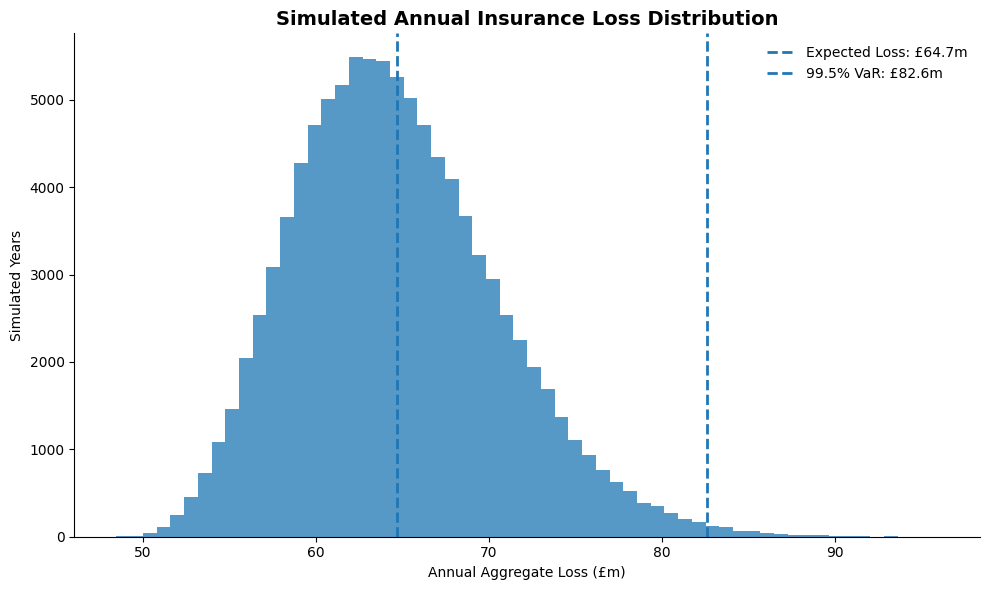

In [22]:
# Annual aggregate-loss distribution with capital thresholds

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    annual_aggregate_losses / 1_000_000,
    bins=60,
    alpha=0.75
)

ax.axvline(
    expected_loss / 1_000_000,
    linestyle="--",
    linewidth=2,
    label=f"Expected Loss: £{expected_loss/1_000_000:.1f}m"
)

ax.axvline(
    var_995 / 1_000_000,
    linestyle="--",
    linewidth=2,
    label=f"99.5% VaR: £{var_995/1_000_000:.1f}m"
)

ax.set_title(
    "Simulated Annual Insurance Loss Distribution",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Annual Aggregate Loss (£m)")
ax.set_ylabel("Simulated Years")

ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/annual_loss_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

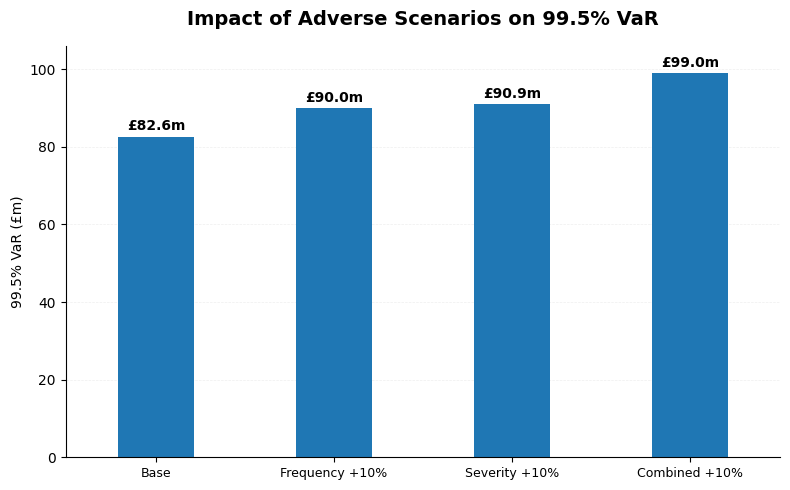

In [41]:
# Professional compact 99.5% VaR stress scenario chart

plot_data = stress_results.copy()

# Tighter category positions
x = np.array([0.0, 0.75, 1.50, 2.25])

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    x,
    plot_data["VaR_99.5"] / 1_000_000,
    width=0.32
)

# Value labels
for bar, value in zip(bars, plot_data["VaR_99.5"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"£{value / 1_000_000:.1f}m",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Impact of Adverse Scenarios on 99.5% VaR",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_ylabel("99.5% VaR (£m)", fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(
    plot_data["Scenario"],
    fontsize=9
)

# Compact plotting area
ax.set_xlim(-0.38, 2.63)
ax.set_ylim(0, 106)

ax.yaxis.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.20
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/stress_scenario_var.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

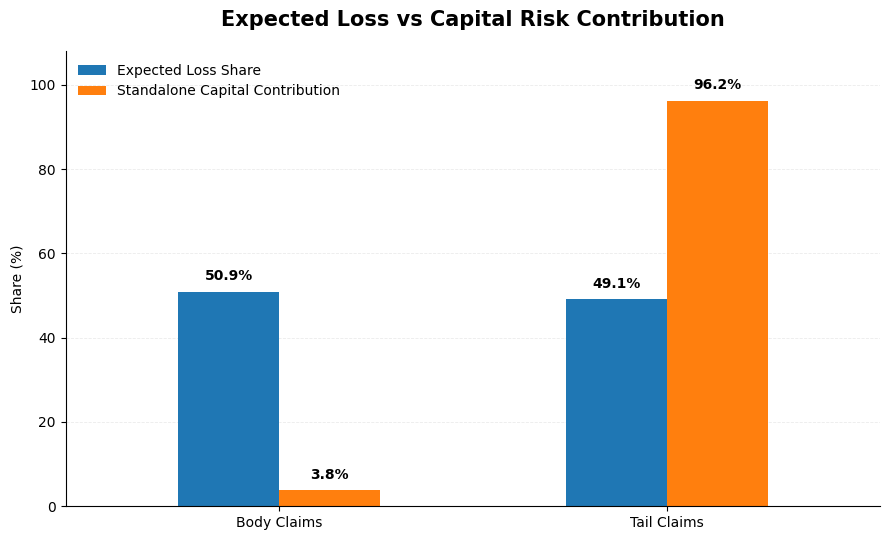

In [43]:
# Expected loss share vs standalone capital contribution

comparison = pd.DataFrame({
    "Risk Component": ["Body Claims", "Tail Claims"],
    "Expected Loss Share": [50.90, 49.10],
    "Capital Contribution": [3.77, 96.23]
})

x = np.arange(len(comparison))
width = 0.26

fig, ax = plt.subplots(figsize=(9, 5.5))

bars1 = ax.bar(
    x - width / 2,
    comparison["Expected Loss Share"],
    width=width,
    label="Expected Loss Share"
)

bars2 = ax.bar(
    x + width / 2,
    comparison["Capital Contribution"],
    width=width,
    label="Standalone Capital Contribution"
)

# Value labels
for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 2,
            f"{bar.get_height():.1f}%",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

ax.set_title(
    "Expected Loss vs Capital Risk Contribution",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_ylabel("Share (%)")
ax.set_xticks(x)
ax.set_xticklabels(comparison["Risk Component"])

ax.set_ylim(0, 108)
ax.set_xlim(-0.55, 1.55)

ax.yaxis.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

ax.set_axisbelow(True)
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/capital_risk_contribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Management Conclusions

The capital model highlights a clear distinction between expected claims cost and the risks that drive unexpected loss.

### Key Findings

- **Expected annual insurance loss is approximately £64.7m**, based on the simulated frequency–severity model.
- At the **99.5% confidence level**, annual losses increase to approximately **£82.6m**, implying **£17.9m of unexpected loss above the expected loss level**.
- The corresponding **99.5% TVaR is £85.2m**, indicating that losses become materially more severe once the VaR threshold is breached.
- Large-loss tail claims account for approximately **49.1% of expected losses but 96.2% of standalone unexpected-loss capital**, demonstrating that capital risk is driven primarily by severe claims rather than ordinary claim volume.
- A **10% severity deterioration** increases 99.5% VaR to approximately **£90.9m**, compared with **£90.0m** under a 10% frequency deterioration.
- Under the combined frequency and severity stress, 99.5% VaR increases to approximately **£99.0m**, around **19.8% above the base capital threshold**.
- Combining body and tail risks produces a modelled diversification benefit of approximately **£0.72m (3.85%)** relative to the sum of standalone unexpected-loss capital.

### Management Implications

The analysis suggests that management attention should focus particularly on controlling exposure to large claims. Potential responses include reviewing underwriting limits, monitoring large-loss experience, assessing reinsurance protection and regularly stress-testing severity assumptions.

The model also demonstrates that monitoring expected loss alone would provide an incomplete view of the insurer's risk position. Tail behaviour and adverse scenarios materially influence the level of financial resources required to withstand severe insurance-loss outcomes.

### Scope and Limitations

This project is a simplified insurance-risk capital model developed for analytical purposes. The 99.5% VaR measure is used as a capital-risk reference point and **should not be interpreted as a regulatory Solvency Capital Requirement (SCR)**.

The model focuses on insurance claim frequency and severity risk and does not incorporate the full range of risks that would be required in an insurer's regulatory or economic capital framework, including market, counterparty/default and operational risk. Results are also dependent on the selected severity distribution, large-loss threshold, modelling limit and independence assumptions.

In [44]:
# Export final capital model result tables

capital_results.to_csv(
    "../outputs/tables/capital_risk_metrics.csv",
    index=False
)

stress_results.to_csv(
    "../outputs/tables/stress_scenario_results.csv",
    index=False
)

diversification_results.to_csv(
    "../outputs/tables/diversification_results.csv",
    index=False
)

capital_contribution.to_csv(
    "../outputs/tables/capital_contribution.csv",
    index=False
)

print("Final capital model tables exported successfully.")

Final capital model tables exported successfully.


In [45]:
# Final model QA checks

qa_checks = {
    "Expected annual loss (£m)": expected_loss / 1_000_000,
    "99.5% VaR (£m)": var_995 / 1_000_000,
    "99.5% TVaR (£m)": tvar_995 / 1_000_000,
    "Unexpected loss (£m)": unexpected_995 / 1_000_000,
    "Capital uplift over EL (%)": capital_uplift * 100,
    "Combined stress VaR (£m)": (
        stress_results.loc[
            stress_results["Scenario"] == "Combined +10%",
            "VaR_99.5"
        ].iloc[0] / 1_000_000
    ),
    "Diversification benefit (£m)": diversification_benefit / 1_000_000,
    "Diversification benefit (%)": diversification_pct * 100,
    "Tail capital contribution (%)": (
        capital_contribution.loc[
            capital_contribution["RiskComponent"] == "Tail Claims",
            "CapitalContributionPct"
        ].iloc[0] * 100
    )
}

qa_results = pd.Series(qa_checks, name="Result")

qa_results.round(2)

Expected annual loss (£m)        64.68
99.5% VaR (£m)                   82.63
99.5% TVaR (£m)                  85.17
Unexpected loss (£m)             17.94
Capital uplift over EL (%)       27.74
Combined stress VaR (£m)         98.97
Diversification benefit (£m)      0.72
Diversification benefit (%)       3.85
Tail capital contribution (%)    96.23
Name: Result, dtype: float64